# Configuring
Before anything, we first need to configure our SDR.
We use the adi python library to do so, with its **ad9361**, not the Pluto one, which does not let us interface both antennas.
We juste need to configure some things, such as the sample rate, center frequency and we can proceed to record using the ```sdr.rx()``` method, which returns 2 lists in one, corresponding to the signal received by its repsecting antennas. For now, we just use it to empty the buffer

In [1]:
import numpy as np
import adi
import matplotlib.pyplot as plt


SAMPLE_RATE = 1e6 # Hz
CENTER_FREQUENCY = 2.432e9 # Hz
NUM_SAMPS = 100000 # number of samples per call to rx()
WAVE_LENGTH = 3*10**8/CENTER_FREQUENCY

ANTENNAS_DISTANCE = WAVE_LENGTH/2 #m

sdr = adi.ad9361("ip:192.168.2.1")
sdr.rx_enabled_channels = [0, 1] # active RX0 et RX1
sdr.sample_rate = int(SAMPLE_RATE)

# Config Rx
sdr.rx_lo = int(CENTER_FREQUENCY)
sdr.rx_rf_bandwidth = int(SAMPLE_RATE)
sdr.rx_buffer_size = NUM_SAMPS
sdr.gain_control_mode_chan0 = 'manual'
sdr.rx_hardwaregain_chan0 = 0.0 # dB
sdr.gain_control_mode_chan1 = 'manual'
sdr.rx_hardwaregain_chan1 = 0.0 # dB

# Clear buffer just to be safe
for i in range (0, 10):
    raw_data = sdr.rx()

# Calibrating

Once the SDR is configured to receive on both its antennas, we can proceed to the calibration step. We plug in the esp directly, through an **atténuateur** and a divider.
The same signal is thus sent to both antennas and we can calculate $\phi_0$. It represents the phase difference of the perpendicular, when the esp is perfectly in front of the SDR, when the signal arrives exactly at the same time to the two antennas.

In [2]:
SEUIL = 20 # dB

def compute_phase_difference(rx0, rx1):
    p = np.abs(rx0)**2 + np.abs(rx1)**2
    mask = p > SEUIL**2

    if np.sum(mask) == 0:
        return np.nan  # No valid samples, return NaN phase difference

    rx0 = rx0[mask]
    rx1 = rx1[mask]

    cross = np.sum(rx0 * np.conj(rx1))
    phi = np.degrees(np.angle(cross))
    return phi

In [3]:
from time import sleep

N_CALIBRATIONS = 10

phis = []

for _ in range(N_CALIBRATIONS):

    # Receive samples
    rx_samples = sdr.rx()
    rx0 = rx_samples[0] # RX0
    rx1 = rx_samples[1] # RX1

    phi = compute_phase_difference(rx0, rx1)
    
    if phi is np.nan:
        raise ValueError("No valid samples received. Please ensure you are directly connected to ESP.")

    phis.append(phi)
    sleep(0.1)

print(f"Mean phase difference between RX0 and RX1: {np.mean(phis):.2f} degrees")
plt.plot(phis, "*")
plt.xlabel("Calibration iteration")
plt.ylabel("Phase difference (degrees)")
plt.ylim([min(phis)-5, max(phis)+5])
phi_0 = np.mean(phis)

ValueError: No valid samples received. Please ensure you are directly connected to ESP.

# Meauring
We can now unplug the divider and plus in the antennas. We the proceeds to take measure.

In [4]:
N_MEASURES = 10

# Clear buffer just to be safe
for i in range (0, 10):
    raw_data = sdr.rx()

measures = []

for _ in range(10):
    # Receive samples
    rx_samples = sdr.rx()
    measures.append(rx_samples)

# Interpreting
Once we have the two signals, we can then do some math and find the phase of eache point, for each signal. We can then make some plot and try to find our signal and the difference in phase between the twos.

Mean delta phi = -144.4288406631625°


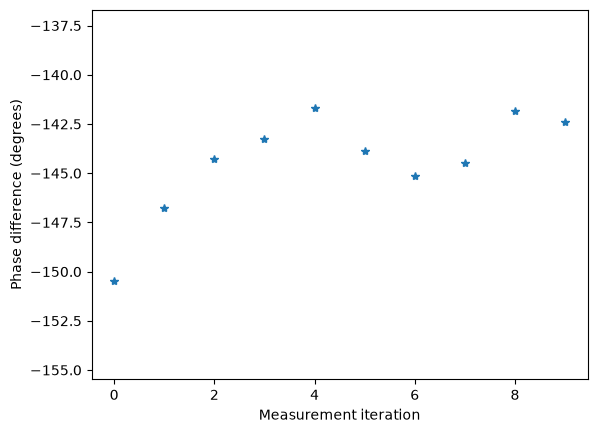

In [5]:
phis = []

for measure in measures:
    phi = compute_phase_difference(measure[0], measure[1])
    phis.append(phi)


print(f"Mean delta phi = {np.mean(phis)}°")

plt.plot(phis, "*")
plt.xlabel("Measurement iteration")
plt.ylabel("Phase difference (degrees)")
plt.ylim([min(phis)-5, max(phis)+5])
plt.show()

# Direct
Small piece of code to see phi in continue

In [6]:
# HELPERS cell

def compute_angle(dp):
    dp = np.radians(dp)
    for n in range(10):
            theta = np.acos((dp-n*2*np.pi)/(2*np.pi*ANTENNAS_DISTANCE/WAVE_LENGTH))
            if not np.isnan(theta):
                return np.degrees(theta)
            
            print(f"N={n} is not a good candidate")
            print(f"Trying for N={-n}")

            n = -n
            theta = np.acos((dp-n*2*np.pi)/(2*np.pi*ANTENNAS_DISTANCE/WAVE_LENGTH))
            
            if not np.isnan(theta):
                return np.degrees(theta)

            print(f"N={-n} is not a good candidate")

    return 0


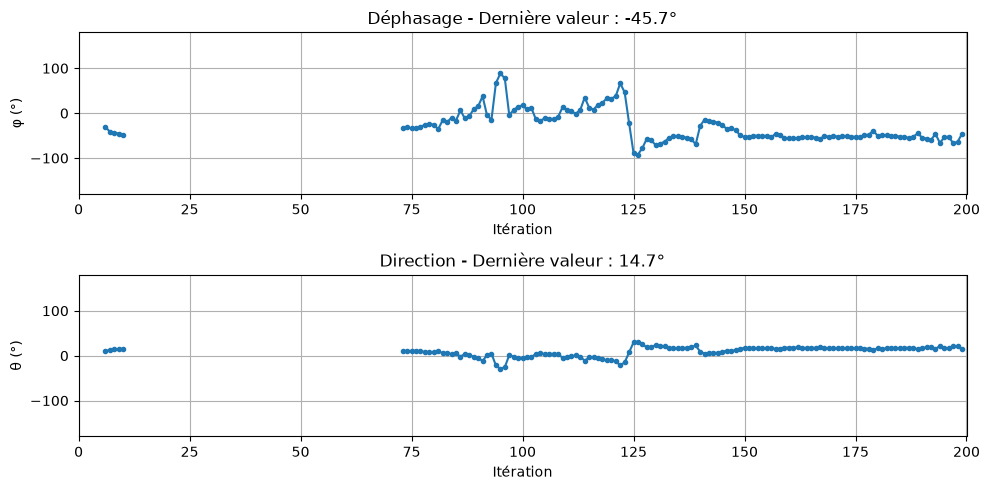

ERROR: READ LINE: -32
ERROR: READ INTEGER: -32


BrokenPipeError: [Errno 32] Broken pipe

In [12]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

N_POINTS = 200

phis = []
thetas = []


try:
    phi_0
except NameError:
    print("Calibration phase difference (phi_0) is not set. Please run the calibration step first.")
    print("Using default value of phi_0 = -165.5 degrees for demonstration purposes.")
    phi_0 = -165.03

try:
    while True:
        rx_samples = sdr.rx()
        rx0 = rx_samples[0]
        rx1 = rx_samples[1]

        phi = compute_phase_difference(rx0, rx1)

        if phi is np.nan:
            theta = np.nan  # Assign NaN to thetas if no valid samples are received
        else:            
            phi = phi - phi_0  # Subtract the calibration phase difference
            phi = (phi + 180) % 360 - 180  # Wrap phi to [-180, 180]
            theta = compute_angle(phi)-90

        phis.append(phi)
        thetas.append(theta)

        phis = phis[-N_POINTS:]  # Keep only the last N_POINTS values
        thetas = thetas[-N_POINTS:]  # Keep only the last N_POINTS values

        clear_output(wait=True)
        plt.figure(figsize=(10, 5))
        plt.subplot(2, 1, 1)
        plt.plot(phis, '.-')
        plt.ylim(-180, 180)
        plt.xlim(0, N_POINTS)
        plt.xlabel("Itération")
        plt.ylabel("φ (°)")
        plt.title(f"Déphasage - Dernière valeur : {phi:.1f}°")
        plt.grid(True)

        plt.subplot(2, 1, 2)
        plt.plot(thetas, '.-')
        plt.ylim(-180, 180)
        plt.xlim(0, N_POINTS)
        plt.xlabel("Itération")
        plt.ylabel("θ (°)")
        plt.title(f"Direction - Dernière valeur : {theta:.1f}°")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

except KeyboardInterrupt:
    print("Arrêt.")